# Collaborative Filtering — Implicit Feedback & Top-K Recommendation

**Task:** Future user–item interaction prediction and Top-K ranking.

**Interaction definition:** An observed user–movie record is a positive interaction. The original rating value is not loaded, transformed, used as a feature, or used as a relevance threshold.

**Evaluation protocol:** Per-user chronological Leave-Two-Out, full-candidate ranking, validation-based model selection, and a held-out test set.

## Thư viện

In [1]:
import os
import json
import time
import copy
import random
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.sparse import csr_matrix
from tqdm.auto import tqdm

try:
    import implicit
    IMPLICIT_AVAILABLE = True
except ImportError:
    implicit = None
    IMPLICIT_AVAILABLE = False

warnings.filterwarnings("ignore", category=FutureWarning)

c:\Users\THUYEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print(f"PyTorch version: {torch.__version__}")
print(f"PyTorch CUDA available: {torch.cuda.is_available()}")
print(f"implicit package available: {IMPLICIT_AVAILABLE}")

PyTorch version: 2.14.1+cpu
PyTorch CUDA available: False
implicit package available: True


In [3]:
def set_all_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_all_seeds(42)

In [4]:
def print_per_epoch(epoch, epochs, metrics):
    postfix = " | ".join(
        f"{name}: {value:.5f}" if isinstance(value, (float, int, np.number)) else f"{name}: {value}"
        for name, value in metrics.items()
    )
    print(f"Epoch {epoch:02d}/{epochs:02d} | {postfix}")


def save_history(history, path):
    if history:
        pd.DataFrame(history).to_csv(path, index=False)
        print(f"[Saved] {path}")

## Cấu hình

In [5]:
class Config:
    DATA_DIR = Path("../data")
    FINAL_DATA_DIR = DATA_DIR / "final_data"
    ARTIFACT_DIR = DATA_DIR / "artifacts"
    CF_DIR = ARTIFACT_DIR / "cf"

    # File nguồn có thể chứa cột rating; pipeline chỉ đọc user, item và timestamp.
    INTERACTIONS_PATH = FINAL_DATA_DIR / "ratings_filtered_by_movie.csv"

    USER_COL = "userId"
    ITEM_COL = "movieId"
    TIMESTAMP_COL = "timestamp"

    MAX_ROWS_TO_PROCESS = 1_000_000
    CHUNK_SIZE = 200_000
    MIN_INTERACTIONS = 20

    # Per-user chronological Leave-Two-Out.
    TRAIN_SPLIT_NAME = "per_user_leave_two_out"

    EMBEDDING_DIM = 64
    INIT_STD = 0.01
    BATCH_SIZE = 4096
    EPOCHS = 15
    LEARNING_RATE_BPR = 1e-3
    LEARNING_RATE_NCF = 1e-3
    WEIGHT_DECAY = 1e-6
    DROPOUT_RATE = 0.2

    NUM_NEGATIVES = 4
    NEGATIVE_SAMPLER = "uniform"
    NEGATIVE_MAX_ATTEMPTS = 100

    TOP_K_LIST = [10, 20, 30, 50]
    PRIMARY_K = 10
    VALIDATION_K_LIST = [10, 20]
    VALIDATION_EVERY = 1
    EARLY_STOPPING_PATIENCE = 3
    EARLY_STOPPING_MIN_DELTA = 1e-4

    SCORE_BATCH_SIZE = 4096
    ALS_FACTORS = 64
    ALS_ALPHA = 40.0
    ALS_REGULARIZATION = 0.05
    ALS_ITERATIONS_GRID = [5, 10, 15, 20, 30]

    RANDOM_STATE = 42
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

    RUN_DIR = CF_DIR / RUN_ID
    CHECKPOINT_DIR = RUN_DIR / "checkpoints"
    LOG_DIR = RUN_DIR / "logs"
    RESULT_DIR = RUN_DIR / "results"

    @classmethod
    def setup(cls):
        for path in [cls.RUN_DIR, cls.CHECKPOINT_DIR, cls.LOG_DIR, cls.RESULT_DIR]:
            path.mkdir(parents=True, exist_ok=True)
        print(f"[INFO] Device: {cls.DEVICE}")
        print(f"[INFO] Run ID: {cls.RUN_ID}")
        print(f"[INFO] Output: {cls.RUN_DIR}")


Config.setup()
set_all_seeds(Config.RANDOM_STATE)

[INFO] Device: cpu
[INFO] Run ID: 20261107_154606
[INFO] Output: ..\data\artifacts\cf\20261107_154606


## Xử lý dữ liệu

### Interaction representation

Với tập user $U$, item $I$, và các bản ghi tương tác quan sát được $D^+$:

$$
y_{ui} =
\begin{cases}
1, & (u,i)\in D^+\\
0, & (u,i)\notin D^+
\end{cases}
$$

$ y_{ui}=0 $ biểu thị unobserved interaction, không xác nhận dislike.

Rating không được sử dụng trong preprocessing hoặc mô hình. Mỗi bản ghi user–item được chuyển thành một positive interaction.

### Temporal Leave-Two-Out

Với mỗi user, các tương tác được sắp xếp theo timestamp:

- Train: tất cả tương tác trừ hai tương tác cuối.
- Validation: tương tác áp chót.
- Test: tương tác cuối.

Các item chưa xuất hiện trong tập huấn luyện tương ứng được xem là cold-start và không đưa vào candidate set của lần đánh giá đó.

In [6]:
def _read_recent_interactions(
    csv_path,
    user_col,
    item_col,
    timestamp_col,
    max_rows,
    chunk_size,
):
    required_cols = [user_col, item_col, timestamp_col]
    recent = pd.DataFrame()

    for chunk in pd.read_csv(
        csv_path,
        usecols=required_cols,
        chunksize=chunk_size,
    ):
        chunk[timestamp_col] = pd.to_numeric(
            chunk[timestamp_col], errors="coerce"
        )
        recent = pd.concat([recent, chunk], ignore_index=True)
        if len(recent) > max_rows:
            recent = recent.nlargest(max_rows, timestamp_col)

    recent = recent.dropna(subset=required_cols)
    recent[user_col] = recent[user_col].astype(str)
    recent[item_col] = recent[item_col].astype(str)
    recent[timestamp_col] = pd.to_numeric(
        recent[timestamp_col], errors="coerce"
    )
    recent = recent.dropna(subset=[timestamp_col])
    recent = recent.sort_values(
        [timestamp_col, user_col, item_col], kind="stable"
    )
    recent = recent.drop_duplicates(
        subset=[user_col, item_col], keep="last"
    )
    return recent.reset_index(drop=True)


def preprocess_interactions(
    csv_path,
    user_col=Config.USER_COL,
    item_col=Config.ITEM_COL,
    timestamp_col=Config.TIMESTAMP_COL,
    max_rows=Config.MAX_ROWS_TO_PROCESS,
    min_interactions=Config.MIN_INTERACTIONS,
    chunk_size=Config.CHUNK_SIZE,
):
    if not Path(csv_path).exists():
        raise FileNotFoundError(
            f"Interaction file not found: {csv_path}. "
            "Update Config.INTERACTIONS_PATH."
        )

    interactions = _read_recent_interactions(
        csv_path=csv_path,
        user_col=user_col,
        item_col=item_col,
        timestamp_col=timestamp_col,
        max_rows=max_rows,
        chunk_size=chunk_size,
    )

    user_counts = interactions[user_col].value_counts()
    users_keep = user_counts[user_counts >= min_interactions].index
    interactions = interactions[
        interactions[user_col].isin(users_keep)
    ].copy()

    interactions = interactions.sort_values(
        [user_col, timestamp_col, item_col], kind="stable"
    ).reset_index(drop=True)

    user_values = interactions[user_col].drop_duplicates().tolist()
    item_values = interactions[item_col].drop_duplicates().tolist()

    user_mapping = {value: idx for idx, value in enumerate(user_values)}
    item_mapping = {value: idx for idx, value in enumerate(item_values)}

    interactions["user_idx"] = interactions[user_col].map(user_mapping).astype("int64")
    interactions["item_idx"] = interactions[item_col].map(item_mapping).astype("int64")
    interactions["label"] = np.int8(1)

    train_parts, val_parts, test_parts = [], [], []
    for _, group in interactions.groupby("user_idx", sort=False):
        if len(group) < min_interactions:
            continue
        train_parts.append(group.iloc[:-2])
        val_parts.append(group.iloc[-2:-1])
        test_parts.append(group.iloc[-1:])

    train_df = pd.concat(train_parts, ignore_index=True)
    val_df = pd.concat(val_parts, ignore_index=True)
    test_df = pd.concat(test_parts, ignore_index=True)

    keep_cols = [
        user_col, item_col, timestamp_col,
        "user_idx", "item_idx", "label"
    ]
    train_df = train_df[keep_cols].copy()
    val_df = val_df[keep_cols].copy()
    test_df = test_df[keep_cols].copy()

    user_mapping_path = Config.RUN_DIR / "user_mapping.json"
    item_mapping_path = Config.RUN_DIR / "item_mapping.json"

    with open(user_mapping_path, "w", encoding="utf-8") as f:
        json.dump(user_mapping, f, ensure_ascii=False)
    with open(item_mapping_path, "w", encoding="utf-8") as f:
        json.dump(item_mapping, f, ensure_ascii=False)

    for name, frame in [
        ("train", train_df), ("validation", val_df), ("test", test_df)
    ]:
        frame.to_parquet(Config.RUN_DIR / f"{name}.parquet", index=False)

    n_users = len(user_mapping)
    n_items = len(item_mapping)
    sparsity = 1.0 - len(interactions) / max(n_users * n_items, 1)

    print("=" * 72)
    print(f"Interactions: {len(interactions):,}")
    print(f"Users: {n_users:,} | Items: {n_items:,}")
    print(f"Train: {len(train_df):,}")
    print(f"Validation: {len(val_df):,}")
    print(f"Test: {len(test_df):,}")
    print(f"Sparsity: {sparsity:.4%}")
    print(f"Rating column loaded: No")
    print("=" * 72)

    return (
        train_df, val_df, test_df,
        user_mapping, item_mapping,
    )


(
    train_df,
    val_df,
    test_df,
    user_mapping,
    item_mapping,
) = preprocess_interactions(Config.INTERACTIONS_PATH)

num_users = len(user_mapping)
num_items = len(item_mapping)

train_val_df = pd.concat(
    [train_df, val_df], ignore_index=True
).drop_duplicates(["user_idx", "item_idx"])

train_candidate_items = np.sort(
    train_df["item_idx"].unique().astype(np.int64)
)
test_candidate_items = np.sort(
    train_val_df["item_idx"].unique().astype(np.int64)
)

print(f"num_users={num_users:,} | num_items={num_items:,}")
print(f"Validation candidates={len(train_candidate_items):,}")
print(f"Test candidates={len(test_candidate_items):,}")

Interactions: 697,358
Users: 13,140 | Items: 2,557
Train: 671,078
Validation: 13,140
Test: 13,140
Sparsity: 97.9245%
Rating column loaded: No
num_users=13,140 | num_items=2,557
Validation candidates=2,537
Test candidates=2,545


## Các hàm đánh giá

### Full-candidate ranking

Với user \(u\), candidate set tại thời điểm đánh giá:

$$
C_u(t)=I_{\mathrm{available}}(t)\setminus I_u^{\mathrm{history}}(t)
$$

Điểm xếp hạng:

$$
\hat{s}_{ui}=f_\theta(u,i), \quad i\in C_u(t)
$$

Danh sách gợi ý:

$$
TopK(u)=\operatorname{arg\,topK}_{i\in C_u(t)}\hat{s}_{ui}
$$

### Metrics

$$
Precision@K=\frac{|TopK(u)\cap R_u|}{K}
$$

$$
Recall@K=\frac{|TopK(u)\cap R_u|}{|R_u|}
$$

$$
HR@K=\mathbb{1}[TopK(u)\cap R_u\ne\emptyset]
$$

$$
DCG@K=\sum_{r=1}^{K}\frac{rel_r}{\log_2(r+1)}
$$

$$
NDCG@K=\frac{DCG@K}{IDCG@K}
$$

Metrics được macro-average trên các user có ít nhất một relevant item nằm trong candidate set. Cold-start positives được thống kê riêng.

In [7]:
def build_seen_map(frame):
    return (
        frame.groupby("user_idx")["item_idx"]
        .apply(lambda values: set(map(int, values)))
        .to_dict()
    )


def _topk_from_scores(item_ids, scores, max_k):
    if len(item_ids) == 0:
        return np.asarray([], dtype=np.int64)

    max_k = min(int(max_k), len(item_ids))
    order = np.lexsort((item_ids, -scores))
    return item_ids[order[:max_k]]


def _user_ranking_metrics(recommended, relevant, ks):
    result = {}
    relevant = set(relevant)

    first_hit_rank = None
    for rank, item_id in enumerate(recommended, start=1):
        if int(item_id) in relevant:
            first_hit_rank = rank
            break

    for k in ks:
        top_items = recommended[:k]
        hit_count = sum(int(item_id) in relevant for item_id in top_items)

        precision = hit_count / k
        recall = hit_count / len(relevant) if relevant else 0.0
        hit_rate = float(hit_count > 0)

        dcg = sum(
            1.0 / np.log2(rank + 1)
            for rank, item_id in enumerate(top_items, start=1)
            if int(item_id) in relevant
        )
        ideal_hits = min(len(relevant), k)
        idcg = sum(
            1.0 / np.log2(rank + 1)
            for rank in range(1, ideal_hits + 1)
        )
        ndcg = dcg / idcg if idcg > 0 else 0.0

        mrr = (
            1.0 / first_hit_rank
            if first_hit_rank is not None and first_hit_rank <= k
            else 0.0
        )

        result[f"Precision@{k}"] = precision
        result[f"Recall@{k}"] = recall
        result[f"HR@{k}"] = hit_rate
        result[f"NDCG@{k}"] = ndcg
        result[f"MRR@{k}"] = mrr

    return result


def evaluate_full_ranking(
    model,
    eval_df,
    history_df,
    candidate_items,
    ks=Config.TOP_K_LIST,
    verbose=True,
):
    ks = sorted(set(int(k) for k in ks))
    max_k = max(ks)

    seen_map = build_seen_map(history_df)
    candidate_items = np.asarray(
        candidate_items, dtype=np.int64
    )
    candidate_set = set(map(int, candidate_items))

    rows = []
    skipped_no_candidate_relevant = 0
    skipped_no_available_candidate = 0

    for user_idx, group in eval_df.groupby("user_idx", sort=False):
        user_idx = int(user_idx)
        relevant_all = set(map(int, group["item_idx"].values))
        relevant = relevant_all.intersection(candidate_set)

        if not relevant:
            skipped_no_candidate_relevant += 1
            continue

        seen = seen_map.get(user_idx, set())
        available = np.asarray(
            [item for item in candidate_items if int(item) not in seen],
            dtype=np.int64,
        )

        if len(available) == 0:
            skipped_no_available_candidate += 1
            continue

        scores = model.score_items(user_idx, available)
        recommended = _topk_from_scores(
            available, np.asarray(scores, dtype=np.float64), max_k
        )

        rows.append(
            _user_ranking_metrics(recommended, relevant, ks)
        )

    if not rows:
        raise ValueError(
            "No evaluable users. Check candidate items and data split."
        )

    metrics = pd.DataFrame(rows).mean().to_dict()
    metrics["n_users_evaluated"] = len(rows)
    metrics["n_users_total"] = int(eval_df["user_idx"].nunique())
    metrics["n_users_skipped_cold"] = skipped_no_candidate_relevant
    metrics["n_users_skipped_empty_candidates"] = skipped_no_available_candidate
    metrics["candidate_count"] = len(candidate_items)
    metrics["evaluation_coverage"] = (
        len(rows) / max(int(eval_df["user_idx"].nunique()), 1)
    )

    if verbose:
        summary = " | ".join(
            f"NDCG@{k}={metrics[f'NDCG@{k}']:.4f}, "
            f"HR@{k}={metrics[f'HR@{k}']:.4f}"
            for k in ks
        )
        print(
            f"[Full ranking] users={len(rows):,}/"
            f"{eval_df['user_idx'].nunique():,} | {summary}"
        )

    return metrics


def evaluate_model_over_ks(
    model,
    eval_df,
    history_df,
    candidate_items,
    ks=Config.TOP_K_LIST,
):
    return evaluate_full_ranking(
        model=model,
        eval_df=eval_df,
        history_df=history_df,
        candidate_items=candidate_items,
        ks=ks,
        verbose=True,
    )


print(f"[OK] Full-ranking evaluation utilities loaded | device={Config.DEVICE}")

[OK] Full-ranking evaluation utilities loaded | device=cpu


## Mô hình Popularity Baseline

### Interaction Popularity

$$
score(i)=\sum_{u\in U}\mathbb{1}[(u,i)\in D_{\mathrm{train}}]
$$

Các item được xếp hạng theo số lượng interaction trong tập huấn luyện.

In [8]:
class PopularityBaseline:
    name = "Popularity"

    def __init__(self, interactions, num_items):
        counts = interactions.groupby("item_idx").size()
        self.scores = np.zeros(num_items, dtype=np.float32)
        self.scores[counts.index.to_numpy(dtype=np.int64)] = (
            counts.to_numpy(dtype=np.float32)
        )

    def score_items(self, user_idx, item_ids):
        return self.scores[np.asarray(item_ids, dtype=np.int64)]

    def recommend(self, user_idx, seen_items, candidate_items, k=10):
        candidates = np.asarray(
            [i for i in candidate_items if int(i) not in seen_items],
            dtype=np.int64,
        )
        scores = self.score_items(user_idx, candidates)
        return _topk_from_scores(candidates, scores, k)


pop_val_model = PopularityBaseline(train_df, num_items)
pop_val_metrics = evaluate_full_ranking(
    pop_val_model,
    val_df,
    train_df,
    train_candidate_items,
    ks=Config.VALIDATION_K_LIST,
)

pop_model = PopularityBaseline(train_val_df, num_items)

[Full ranking] users=13,132/13,140 | NDCG@10=0.0716, HR@10=0.1410 | NDCG@20=0.0939, HR@20=0.2302


## Mô hình Bayesian Personalized Ranking — Matrix Factorization

### BPR-MF

User và item được biểu diễn bằng latent factors:

$$
\hat{s}_{ui}=p_u^\top q_i
$$

Với positive item \(i\) và sampled unobserved item \(j\):

$$
\hat{s}_{ui}>\hat{s}_{uj}
$$

BPR pairwise objective:

$$
\mathcal{L}_{BPR}
=
-\sum_{(u,i,j)\in D}
\ln\sigma(\hat{s}_{ui}-\hat{s}_{uj})
+\lambda\|\Theta\|_2^2
$$

Negative sampling được áp dụng trong training. Validation và test sử dụng full-candidate ranking.

In [9]:
def build_positive_map(frame):
    return (
        frame.groupby("user_idx")["item_idx"]
        .apply(lambda values: set(map(int, values)))
        .to_dict()
    )


def sample_uniform_negatives(
    user_ids,
    candidate_items,
    user_positive_map,
    num_negatives,
    rng,
    max_attempts=Config.NEGATIVE_MAX_ATTEMPTS,
):
    candidate_items = np.asarray(candidate_items, dtype=np.int64)
    if len(candidate_items) == 0:
        raise ValueError("Negative candidate pool is empty.")

    negatives = np.empty(
        (len(user_ids), num_negatives), dtype=np.int64
    )

    for row, user_id in enumerate(user_ids):
        positives = user_positive_map.get(int(user_id), set())

        for col in range(num_negatives):
            sampled = None

            for _ in range(max_attempts):
                candidate = int(
                    candidate_items[rng.integers(0, len(candidate_items))]
                )
                if candidate not in positives:
                    sampled = candidate
                    break

            if sampled is None:
                valid = np.asarray(
                    [item for item in candidate_items if int(item) not in positives],
                    dtype=np.int64,
                )
                if len(valid) == 0:
                    raise ValueError(
                        f"No negative candidate for user {user_id}."
                    )
                sampled = int(rng.choice(valid))

            negatives[row, col] = sampled

    return negatives


class BPR_MF(nn.Module):
    name = "BPR-MF"

    def __init__(
        self,
        num_users,
        num_items,
        dim=Config.EMBEDDING_DIM,
        init_std=Config.INIT_STD,
    ):
        super().__init__()
        self.user_embedding = nn.Embedding(num_users, dim)
        self.item_embedding = nn.Embedding(num_items, dim)

        nn.init.normal_(self.user_embedding.weight, std=init_std)
        nn.init.normal_(self.item_embedding.weight, std=init_std)

    def forward(self, users, positive_items, negative_items):
        user_vec = self.user_embedding(users)
        positive_vec = self.item_embedding(positive_items)
        negative_vec = self.item_embedding(negative_items)

        positive_scores = (user_vec * positive_vec).sum(dim=-1)
        negative_scores = (user_vec * negative_vec).sum(dim=-1)
        return positive_scores, negative_scores

    @torch.no_grad()
    def score_items(self, user_idx, item_ids):
        self.eval()
        item_tensor = torch.as_tensor(
            item_ids, dtype=torch.long, device=Config.DEVICE
        )
        user_vector = self.user_embedding.weight[int(user_idx)]
        scores = self.item_embedding(item_tensor) @ user_vector
        return scores.detach().cpu().numpy()


def train_bpr(
    model,
    train_frame,
    num_items,
    candidate_items,
    val_frame=None,
    val_history=None,
    val_candidate_items=None,
    epochs=Config.EPOCHS,
    batch_size=Config.BATCH_SIZE,
    lr=Config.LEARNING_RATE_BPR,
    num_negatives=Config.NUM_NEGATIVES,
    patience=Config.EARLY_STOPPING_PATIENCE,
    checkpoint_path=None,
    log_path=None,
    seed=Config.RANDOM_STATE,
):
    model = model.to(Config.DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=Config.WEIGHT_DECAY,
    )

    users = train_frame["user_idx"].to_numpy(dtype=np.int64)
    items = train_frame["item_idx"].to_numpy(dtype=np.int64)
    positive_map = build_positive_map(train_frame)
    rng = np.random.default_rng(seed)

    best_metric = -np.inf
    best_epoch = epochs
    patience_count = 0
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        permutation = rng.permutation(len(users))
        total_loss = 0.0
        total_pairs = 0
        start_time = time.time()

        for start in tqdm(
            range(0, len(permutation), batch_size),
            desc=f"BPR epoch {epoch}/{epochs}",
            leave=False,
        ):
            batch_indices = permutation[start:start + batch_size]
            batch_users = users[batch_indices]
            batch_items = items[batch_indices]

            negative_items = sample_uniform_negatives(
                user_ids=batch_users,
                candidate_items=candidate_items,
                user_positive_map=positive_map,
                num_negatives=num_negatives,
                rng=rng,
            )

            batch_size_actual = len(batch_users)
            user_tensor = torch.as_tensor(
                np.repeat(batch_users, num_negatives),
                dtype=torch.long,
                device=Config.DEVICE,
            )
            positive_tensor = torch.as_tensor(
                np.repeat(batch_items, num_negatives),
                dtype=torch.long,
                device=Config.DEVICE,
            )
            negative_tensor = torch.as_tensor(
                negative_items.reshape(-1),
                dtype=torch.long,
                device=Config.DEVICE,
            )

            positive_scores, negative_scores = model(
                user_tensor, positive_tensor, negative_tensor
            )
            loss = -F.logsigmoid(
                positive_scores - negative_scores
            ).mean()

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            pair_count = len(user_tensor)
            total_loss += float(loss.item()) * pair_count
            total_pairs += pair_count

        train_loss = total_loss / max(total_pairs, 1)
        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "learning_rate": lr,
            "num_negatives": num_negatives,
            "epoch_seconds": time.time() - start_time,
        }

        if (
            val_frame is not None
            and val_history is not None
            and val_candidate_items is not None
            and epoch % Config.VALIDATION_EVERY == 0
        ):
            val_metrics = evaluate_full_ranking(
                model,
                val_frame,
                val_history,
                val_candidate_items,
                ks=Config.VALIDATION_K_LIST,
                verbose=False,
            )
            selection_metric = val_metrics[f"NDCG@{Config.PRIMARY_K}"]
            row.update({
                "val_ndcg@10": val_metrics.get("NDCG@10", np.nan),
                "val_ndcg@20": val_metrics.get("NDCG@20", np.nan),
                "val_hr@10": val_metrics.get("HR@10", np.nan),
                "val_hr@20": val_metrics.get("HR@20", np.nan),
                "val_users": val_metrics["n_users_evaluated"],
                "val_coverage": val_metrics["evaluation_coverage"],
            })

            print_per_epoch(epoch, epochs, {
                "Train BPR Loss": train_loss,
                "Val NDCG@10": selection_metric,
                "Val HR@10": row["val_hr@10"],
                "Seconds": row["epoch_seconds"],
            })

            if selection_metric > best_metric + Config.EARLY_STOPPING_MIN_DELTA:
                best_metric = selection_metric
                best_epoch = epoch
                patience_count = 0
                best_state = copy.deepcopy(model.state_dict())
                if checkpoint_path:
                    torch.save(best_state, checkpoint_path)
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"[Early stopping] best_epoch={best_epoch}, best_val_ndcg@10={best_metric:.5f}")
                    history.append(row)
                    break
        else:
            print_per_epoch(epoch, epochs, {
                "Train BPR Loss": train_loss,
                "Seconds": row["epoch_seconds"],
            })

        history.append(row)

    if best_state is not None:
        model.load_state_dict(best_state)
    elif checkpoint_path:
        torch.save(model.state_dict(), checkpoint_path)

    if log_path:
        save_history(history, log_path)

    return model, best_epoch, pd.DataFrame(history)


set_all_seeds(Config.RANDOM_STATE)
bpr_model_for_selection = BPR_MF(num_users, num_items)
bpr_checkpoint = Config.CHECKPOINT_DIR / "bpr_selection.pt"

bpr_model_for_selection, bpr_best_epoch, bpr_train_history = train_bpr(
    model=bpr_model_for_selection,
    train_frame=train_df,
    num_items=num_items,
    candidate_items=train_candidate_items,
    val_frame=val_df,
    val_history=train_df,
    val_candidate_items=train_candidate_items,
    epochs=Config.EPOCHS,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=bpr_checkpoint,
    log_path=Config.LOG_DIR / "bpr_validation_log.csv",
)

print(f"BPR selected epoch: {bpr_best_epoch}")

set_all_seeds(Config.RANDOM_STATE)
bpr_model = BPR_MF(num_users, num_items)
bpr_model, _, bpr_refit_history = train_bpr(
    model=bpr_model,
    train_frame=train_val_df,
    num_items=num_items,
    candidate_items=test_candidate_items,
    epochs=bpr_best_epoch,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=Config.CHECKPOINT_DIR / "bpr_final.pt",
    log_path=Config.LOG_DIR / "bpr_refit_log.csv",
)


Epoch 01/15 | Train BPR Loss: 0.55643 | Val NDCG@10: 0.06952 | Val HR@10: 0.13745 | Seconds: 22.62799


Epoch 02/15 | Train BPR Loss: 0.18854 | Val NDCG@10: 0.07125 | Val HR@10: 0.14050 | Seconds: 25.05688


Epoch 03/15 | Train BPR Loss: 0.14479 | Val NDCG@10: 0.07139 | Val HR@10: 0.14042 | Seconds: 24.44867


Epoch 04/15 | Train BPR Loss: 0.13605 | Val NDCG@10: 0.07186 | Val HR@10: 0.14164 | Seconds: 22.01098


Epoch 05/15 | Train BPR Loss: 0.13224 | Val NDCG@10: 0.07157 | Val HR@10: 0.14027 | Seconds: 23.76954


Epoch 06/15 | Train BPR Loss: 0.12981 | Val NDCG@10: 0.07208 | Val HR@10: 0.14210 | Seconds: 18.59632


... (20 outputs left out)

Epoch 12/15 | Train BPR Loss: 0.11202 | Seconds: 20.45182


Epoch 13/15 | Train BPR Loss: 0.10907 | Seconds: 19.71728


Epoch 14/15 | Train BPR Loss: 0.10592 | Seconds: 17.17131


Epoch 15/15 | Train BPR Loss: 0.10286 | Seconds: 17.00306
[Saved] ..\data\artifacts\cf\20261107_154606\logs\bpr_refit_log.csv


## Mô hình Alternating Least Squares — Implicit Matrix Factorization

### Weighted Matrix Factorization

$$
\min_{X,Y}
\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2
+\lambda\left(\|X\|_F^2+\|Y\|_F^2\right)
$$

Với implicit feedback:

$$
p_{ui}=\mathbb{1}[r_{ui}>0]
$$

$$
c_{ui}=1+\alpha r_{ui}
$$

$ p_{ui} $ biểu thị preference target; $ c_{ui} $ biểu thị confidence. Các cặp chưa quan sát có confidence thấp hơn các cặp đã tương tác.

ALS tối ưu luân phiên user factors và item factors. Phương pháp sử dụng weighted objective trên ma trận user–item, không dùng sampled pairwise negatives.

In [10]:
if IMPLICIT_AVAILABLE:
    class ALS_Implicit:
        name = "ALS-Implicit"

        def __init__(
            self,
            train_frame,
            num_users,
            num_items,
            factors=Config.ALS_FACTORS,
            alpha=Config.ALS_ALPHA,
            regularization=Config.ALS_REGULARIZATION,
            iterations=15,
            random_state=Config.RANDOM_STATE,
        ):
            interactions = train_frame.drop_duplicates(
                ["user_idx", "item_idx"]
            )
            values = np.ones(len(interactions), dtype=np.float32)

            self.user_items = csr_matrix(
                (
                    values,
                    (
                        interactions["user_idx"].to_numpy(dtype=np.int64),
                        interactions["item_idx"].to_numpy(dtype=np.int64),
                    ),
                ),
                shape=(num_users, num_items),
                dtype=np.float32,
            )

            self.model = implicit.als.AlternatingLeastSquares(
                factors=factors,
                regularization=regularization,
                alpha=alpha,
                iterations=iterations,
                random_state=random_state,
            )
            self.model.fit(self.user_items, show_progress=False)
            self.num_items = num_items
            self.iterations = iterations

        def score_items(self, user_idx, item_ids):
            item_ids = np.asarray(item_ids, dtype=np.int64)
            user_vector = self.model.user_factors[int(user_idx)]
            item_vectors = self.model.item_factors[item_ids]
            return item_vectors @ user_vector

        def recommend(self, user_idx, seen_items, candidate_items, k=10):
            candidates = np.asarray(
                [i for i in candidate_items if int(i) not in seen_items],
                dtype=np.int64,
            )
            scores = self.score_items(user_idx, candidates)
            return _topk_from_scores(candidates, scores, k)
else:
    print("Package 'implicit' is unavailable. Install it before running ALS cells.")

## Chọn cấu hình ALS bằng Validation

Các cấu hình `iterations` được so sánh trên cùng validation candidate set. Cấu hình có Validation NDCG@10 cao nhất được sử dụng cho mô hình cuối.

In [11]:
als_validation_rows = []
als_best_iterations = None
als_best_metric = -np.inf

if IMPLICIT_AVAILABLE:
    for iterations in Config.ALS_ITERATIONS_GRID:
        start_time = time.time()
        candidate_model = ALS_Implicit(
            train_frame=train_df,
            num_users=num_users,
            num_items=num_items,
            factors=Config.ALS_FACTORS,
            alpha=Config.ALS_ALPHA,
            regularization=Config.ALS_REGULARIZATION,
            iterations=iterations,
        )

        metrics = evaluate_full_ranking(
            candidate_model,
            val_df,
            train_df,
            train_candidate_items,
            ks=Config.VALIDATION_K_LIST,
            verbose=False,
        )

        row = {
            "iterations": iterations,
            "val_ndcg@10": metrics["NDCG@10"],
            "val_ndcg@20": metrics["NDCG@20"],
            "val_hr@10": metrics["HR@10"],
            "val_hr@20": metrics["HR@20"],
            "n_users_evaluated": metrics["n_users_evaluated"],
            "seconds": time.time() - start_time,
        }
        als_validation_rows.append(row)
        print(row)

        if row["val_ndcg@10"] > als_best_metric:
            als_best_metric = row["val_ndcg@10"]
            als_best_iterations = iterations

    als_validation_log = pd.DataFrame(als_validation_rows)
    als_validation_log.to_csv(
        Config.LOG_DIR / "als_validation_log.csv", index=False
    )

    als_model = ALS_Implicit(
        train_frame=train_val_df,
        num_users=num_users,
        num_items=num_items,
        factors=Config.ALS_FACTORS,
        alpha=Config.ALS_ALPHA,
        regularization=Config.ALS_REGULARIZATION,
        iterations=als_best_iterations,
    )
    print(f"ALS selected iterations: {als_best_iterations}")
else:
    als_model = None
    als_validation_log = pd.DataFrame()

c:\Users\THUYEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


{'iterations': 5, 'val_ndcg@10': 0.07903866691579652, 'val_ndcg@20': 0.10626514982659023, 'val_hr@10': 0.16448370392933293, 'val_hr@20': 0.273149558330795, 'n_users_evaluated': 13132, 'seconds': 11.341152906417847}
{'iterations': 10, 'val_ndcg@10': 0.07980252117658454, 'val_ndcg@20': 0.10737093953341405, 'val_hr@10': 0.16326530612244897, 'val_hr@20': 0.272844958879074, 'n_users_evaluated': 13132, 'seconds': 10.354878187179565}
{'iterations': 15, 'val_ndcg@10': 0.0813419397801488, 'val_ndcg@20': 0.10913483337446282, 'val_hr@10': 0.16730124885775205, 'val_hr@20': 0.2778708498324703, 'n_users_evaluated': 13132, 'seconds': 10.89615535736084}
{'iterations': 20, 'val_ndcg@10': 0.08190350258169858, 'val_ndcg@20': 0.10984805261311642, 'val_hr@10': 0.16844349680170576, 'val_hr@20': 0.27939384709107523, 'n_users_evaluated': 13132, 'seconds': 11.067683219909668}
{'iterations': 30, 'val_ndcg@10': 0.08172661010915144, 'val_ndcg@20': 0.10953988042038959, 'val_hr@10': 0.16821504721291503, 'val_hr@20'

## Mô hình Neural Collaborative Filtering

### Binary Cross-Entropy

Với positive interactions $D^+$ và sampled unobserved pairs $D^-_s$:

$$
\mathcal{L}_{BCE}
=
-\sum_{(u,i)\in D^+}\log\sigma(s_{ui})
-\sum_{(u,j)\in D^-_s}\log(1-\sigma(s_{uj}))
$$

Trong cấu hình mặc định:

$$
|D^-_s|=4|D^+|
$$

Negative samples là unobserved proxies. Tỷ lệ positive/negative được giữ nhất quán trong batch.

Negative candidate pool được giới hạn trong item catalog xuất hiện ở Train và loại các positive đã quan sát của user trong Train. Các tương tác Validation/Test diễn ra sau thời điểm Train vẫn là unobserved tại thời điểm huấn luyện và có thể được lấy mẫu như negative proxies; đây là giới hạn của implicit-feedback sampling.

In [12]:
def train_ncf(
    model,
    train_frame,
    num_items,
    candidate_items,
    val_frame=None,
    val_history=None,
    val_candidate_items=None,
    epochs=Config.EPOCHS,
    batch_size=Config.BATCH_SIZE,
    lr=Config.LEARNING_RATE_NCF,
    num_negatives=Config.NUM_NEGATIVES,
    patience=Config.EARLY_STOPPING_PATIENCE,
    checkpoint_path=None,
    log_path=None,
    seed=Config.RANDOM_STATE,
):
    model = model.to(Config.DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=Config.WEIGHT_DECAY,
    )

    users = train_frame["user_idx"].to_numpy(dtype=np.int64)
    items = train_frame["item_idx"].to_numpy(dtype=np.int64)
    positive_map = build_positive_map(train_frame)
    rng = np.random.default_rng(seed)

    best_metric = -np.inf
    best_epoch = epochs
    patience_count = 0
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        permutation = rng.permutation(len(users))
        total_loss = 0.0
        total_examples = 0
        start_time = time.time()

        for start in tqdm(
            range(0, len(permutation), batch_size),
            desc=f"{model.name} epoch {epoch}/{epochs}",
            leave=False,
        ):
            batch_indices = permutation[start:start + batch_size]
            batch_users = users[batch_indices]
            batch_items = items[batch_indices]

            negative_items = sample_uniform_negatives(
                user_ids=batch_users,
                candidate_items=candidate_items,
                user_positive_map=positive_map,
                num_negatives=num_negatives,
                rng=rng,
            )

            positive_users_tensor = torch.as_tensor(
                batch_users, dtype=torch.long, device=Config.DEVICE
            )
            positive_items_tensor = torch.as_tensor(
                batch_items, dtype=torch.long, device=Config.DEVICE
            )

            negative_users_tensor = torch.as_tensor(
                np.repeat(batch_users, num_negatives),
                dtype=torch.long,
                device=Config.DEVICE,
            )
            negative_items_tensor = torch.as_tensor(
                negative_items.reshape(-1),
                dtype=torch.long,
                device=Config.DEVICE,
            )

            positive_logits = model(
                positive_users_tensor, positive_items_tensor
            )
            negative_logits = model(
                negative_users_tensor, negative_items_tensor
            )

            logits = torch.cat([positive_logits, negative_logits])
            labels = torch.cat([
                torch.ones_like(positive_logits),
                torch.zeros_like(negative_logits),
            ])

            loss = F.binary_cross_entropy_with_logits(logits, labels)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            batch_examples = len(labels)
            total_loss += float(loss.item()) * batch_examples
            total_examples += batch_examples

        train_loss = total_loss / max(total_examples, 1)
        row = {
            "epoch": epoch,
            "train_bce_loss": train_loss,
            "learning_rate": lr,
            "num_negatives_per_positive": num_negatives,
            "positive_negative_ratio": f"1:{num_negatives}",
            "epoch_seconds": time.time() - start_time,
        }

        if (
            val_frame is not None
            and val_history is not None
            and val_candidate_items is not None
            and epoch % Config.VALIDATION_EVERY == 0
        ):
            val_metrics = evaluate_full_ranking(
                model,
                val_frame,
                val_history,
                val_candidate_items,
                ks=Config.VALIDATION_K_LIST,
                verbose=False,
            )
            selection_metric = val_metrics[f"NDCG@{Config.PRIMARY_K}"]
            row.update({
                "val_ndcg@10": val_metrics.get("NDCG@10", np.nan),
                "val_ndcg@20": val_metrics.get("NDCG@20", np.nan),
                "val_hr@10": val_metrics.get("HR@10", np.nan),
                "val_hr@20": val_metrics.get("HR@20", np.nan),
                "val_users": val_metrics["n_users_evaluated"],
                "val_coverage": val_metrics["evaluation_coverage"],
            })

            print_per_epoch(epoch, epochs, {
                "Train BCE": train_loss,
                "Val NDCG@10": selection_metric,
                "Val HR@10": row["val_hr@10"],
                "Seconds": row["epoch_seconds"],
            })

            if selection_metric > best_metric + Config.EARLY_STOPPING_MIN_DELTA:
                best_metric = selection_metric
                best_epoch = epoch
                patience_count = 0
                best_state = copy.deepcopy(model.state_dict())
                if checkpoint_path:
                    torch.save(best_state, checkpoint_path)
            else:
                patience_count += 1
                if patience_count >= patience:
                    print(f"[Early stopping] best_epoch={best_epoch}, best_val_ndcg@10={best_metric:.5f}")
                    history.append(row)
                    break
        else:
            print_per_epoch(epoch, epochs, {
                "Train BCE": train_loss,
                "Seconds": row["epoch_seconds"],
            })

        history.append(row)

    if best_state is not None:
        model.load_state_dict(best_state)
    elif checkpoint_path:
        torch.save(model.state_dict(), checkpoint_path)

    if log_path:
        save_history(history, log_path)

    return model, best_epoch, pd.DataFrame(history)

### GMF NCF Model

### Generalized Matrix Factorization

$$
\mathbf{z}_{ui}=\mathbf{p}_u\odot\mathbf{q}_i
$$

$$
s_{ui}=\mathbf{h}^{\top}\mathbf{z}_{ui}+b
$$

GMF sử dụng element-wise product giữa user embedding và item embedding.

In [13]:
class GMF_NCF(nn.Module):
    name = "GMF"

    def __init__(
        self,
        num_users,
        num_items,
        dim=32,
        init_std=Config.INIT_STD,
    ):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, dim)
        self.item_emb = nn.Embedding(num_items, dim)
        self.output = nn.Linear(dim, 1)

        nn.init.normal_(self.user_emb.weight, std=init_std)
        nn.init.normal_(self.item_emb.weight, std=init_std)

    def forward(self, users, items):
        interaction = self.user_emb(users) * self.item_emb(items)
        return self.output(interaction).squeeze(-1)

    @torch.no_grad()
    def score_items(self, user_idx, item_ids):
        self.eval()
        item_ids = np.asarray(item_ids, dtype=np.int64)
        outputs = []

        for start in range(0, len(item_ids), Config.SCORE_BATCH_SIZE):
            batch_items = item_ids[start:start + Config.SCORE_BATCH_SIZE]
            users = torch.full(
                (len(batch_items),),
                int(user_idx),
                dtype=torch.long,
                device=Config.DEVICE,
            )
            items = torch.as_tensor(
                batch_items, dtype=torch.long, device=Config.DEVICE
            )
            outputs.append(self(users, items).detach().cpu().numpy())

        return np.concatenate(outputs) if outputs else np.asarray([])

In [14]:
set_all_seeds(Config.RANDOM_STATE)

gmf_selection = GMF_NCF(num_users, num_items, dim=32)
gmf_checkpoint = Config.CHECKPOINT_DIR / "gmf_selection.pt"

gmf_selection, gmf_best_epoch, gmf_train_history = train_ncf(
    model=gmf_selection,
    train_frame=train_df,
    num_items=num_items,
    candidate_items=train_candidate_items,
    val_frame=val_df,
    val_history=train_df,
    val_candidate_items=train_candidate_items,
    epochs=Config.EPOCHS,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=gmf_checkpoint,
    log_path=Config.LOG_DIR / "gmf_validation_log.csv",
)

set_all_seeds(Config.RANDOM_STATE)
gmf_model = GMF_NCF(num_users, num_items, dim=32)
gmf_model, _, gmf_refit_history = train_ncf(
    model=gmf_model,
    train_frame=train_val_df,
    num_items=num_items,
    candidate_items=test_candidate_items,
    epochs=gmf_best_epoch,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=Config.CHECKPOINT_DIR / "gmf_final.pt",
    log_path=Config.LOG_DIR / "gmf_refit_log.csv",
)

Epoch 01/15 | Train BCE: 0.68672 | Val NDCG@10: 0.07072 | Val HR@10: 0.13768 | Seconds: 14.18159


Epoch 02/15 | Train BCE: 0.43609 | Val NDCG@10: 0.07278 | Val HR@10: 0.14225 | Seconds: 14.30357


Epoch 03/15 | Train BCE: 0.27005 | Val NDCG@10: 0.07179 | Val HR@10: 0.14050 | Seconds: 14.46642


Epoch 04/15 | Train BCE: 0.24083 | Val NDCG@10: 0.07168 | Val HR@10: 0.14034 | Seconds: 18.10944


Epoch 05/15 | Train BCE: 0.23219 | Val NDCG@10: 0.07167 | Val HR@10: 0.14004 | Seconds: 21.12295
[Early stopping] best_epoch=2, best_val_ndcg@10=0.07278
[Saved] ..\data\artifacts\cf\20261107_154606\logs\gmf_validation_log.csv


Epoch 01/02 | Train BCE: 0.68626 | Seconds: 16.91574


Epoch 02/02 | Train BCE: 0.43115 | Seconds: 14.59137
[Saved] ..\data\artifacts\cf\20261107_154606\logs\gmf_refit_log.csv


### MLP NCF Model

### Multi-Layer Perceptron

$$
\mathbf{z}_{ui}^{(0)}=[\mathbf{p}_u;\mathbf{q}_i]
$$

$$
\mathbf{z}_{ui}^{(l)}
=
ReLU(W_l^\top\mathbf{z}_{ui}^{(l-1)}+\mathbf{b}_l)
$$

$$
s_{ui}=W_o^\top\mathbf{z}_{ui}^{(L)}+b_o
$$

MLP học tương tác user–item thông qua các hidden layers.

In [15]:
class MLP_NCF(nn.Module):
    name = "MLP-NCF"

    def __init__(
        self,
        num_users,
        num_items,
        dim=64,
        hidden=(64, 32),
        dropout=Config.DROPOUT_RATE,
        init_std=Config.INIT_STD,
    ):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, dim)
        self.item_emb = nn.Embedding(num_items, dim)

        layers = []
        input_dim = dim * 2
        for hidden_dim in hidden:
            layers.extend([
                nn.Linear(input_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            input_dim = hidden_dim

        self.mlp = nn.Sequential(*layers)
        self.output = nn.Linear(input_dim, 1)

        nn.init.normal_(self.user_emb.weight, std=init_std)
        nn.init.normal_(self.item_emb.weight, std=init_std)

    def forward(self, users, items):
        user_vec = self.user_emb(users)
        item_vec = self.item_emb(items)
        features = torch.cat([user_vec, item_vec], dim=-1)
        return self.output(self.mlp(features)).squeeze(-1)

    @torch.no_grad()
    def score_items(self, user_idx, item_ids):
        self.eval()
        item_ids = np.asarray(item_ids, dtype=np.int64)
        outputs = []

        for start in range(0, len(item_ids), Config.SCORE_BATCH_SIZE):
            batch_items = item_ids[start:start + Config.SCORE_BATCH_SIZE]
            users = torch.full(
                (len(batch_items),),
                int(user_idx),
                dtype=torch.long,
                device=Config.DEVICE,
            )
            items = torch.as_tensor(
                batch_items, dtype=torch.long, device=Config.DEVICE
            )
            outputs.append(self(users, items).detach().cpu().numpy())

        return np.concatenate(outputs) if outputs else np.asarray([])

In [16]:
set_all_seeds(Config.RANDOM_STATE)

mlp_selection = MLP_NCF(num_users, num_items)
mlp_checkpoint = Config.CHECKPOINT_DIR / "mlp_selection.pt"

mlp_selection, mlp_best_epoch, mlp_train_history = train_ncf(
    model=mlp_selection,
    train_frame=train_df,
    num_items=num_items,
    candidate_items=train_candidate_items,
    val_frame=val_df,
    val_history=train_df,
    val_candidate_items=train_candidate_items,
    epochs=Config.EPOCHS,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=mlp_checkpoint,
    log_path=Config.LOG_DIR / "mlp_validation_log.csv",
)

set_all_seeds(Config.RANDOM_STATE)
mlp_model = MLP_NCF(num_users, num_items)
mlp_model, _, mlp_refit_history = train_ncf(
    model=mlp_model,
    train_frame=train_val_df,
    num_items=num_items,
    candidate_items=test_candidate_items,
    epochs=mlp_best_epoch,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=Config.CHECKPOINT_DIR / "mlp_final.pt",
    log_path=Config.LOG_DIR / "mlp_refit_log.csv",
)

Epoch 01/15 | Train BCE: 0.36627 | Val NDCG@10: 0.07098 | Val HR@10: 0.13951 | Seconds: 22.33016


Epoch 02/15 | Train BCE: 0.22246 | Val NDCG@10: 0.07255 | Val HR@10: 0.14278 | Seconds: 22.40547


Epoch 03/15 | Train BCE: 0.21888 | Val NDCG@10: 0.07154 | Val HR@10: 0.14141 | Seconds: 23.08915


Epoch 04/15 | Train BCE: 0.21770 | Val NDCG@10: 0.07193 | Val HR@10: 0.14042 | Seconds: 26.63394


Epoch 05/15 | Train BCE: 0.21656 | Val NDCG@10: 0.07188 | Val HR@10: 0.14095 | Seconds: 25.25802
[Early stopping] best_epoch=2, best_val_ndcg@10=0.07255
[Saved] ..\data\artifacts\cf\20261107_154606\logs\mlp_validation_log.csv


Epoch 01/02 | Train BCE: 0.36402 | Seconds: 23.00179


Epoch 02/02 | Train BCE: 0.22242 | Seconds: 23.07895
[Saved] ..\data\artifacts\cf\20261107_154606\logs\mlp_refit_log.csv


### NeuMF — GMF + MLP

$$
\mathbf{z}_{ui}^{GMF}=\mathbf{p}_u^{G}\odot\mathbf{q}_i^{G}
$$

$$
\mathbf{z}_{ui}^{MLP}=MLP([\mathbf{p}_u^{M};\mathbf{q}_i^{M}])
$$

$$
s_{ui}=\mathbf{h}^{\top}
[\mathbf{z}_{ui}^{GMF};\mathbf{z}_{ui}^{MLP}]+b
$$

Hai nhánh GMF và MLP sử dụng embedding riêng, sau đó hợp nhất ở output layer.

In [17]:
class NeuMF(nn.Module):
    name = "NeuMF"

    def __init__(
        self,
        num_users,
        num_items,
        gmf_dim=32,
        mlp_dim=32,
        hidden=(64, 32),
        dropout=Config.DROPOUT_RATE,
        init_std=Config.INIT_STD,
    ):
        super().__init__()

        self.user_emb_gmf = nn.Embedding(num_users, gmf_dim)
        self.item_emb_gmf = nn.Embedding(num_items, gmf_dim)
        self.user_emb_mlp = nn.Embedding(num_users, mlp_dim)
        self.item_emb_mlp = nn.Embedding(num_items, mlp_dim)

        layers = []
        input_dim = mlp_dim * 2
        for hidden_dim in hidden:
            layers.extend([
                nn.Linear(input_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            input_dim = hidden_dim

        self.mlp = nn.Sequential(*layers)
        self.output = nn.Linear(gmf_dim + input_dim, 1)

        for embedding in [
            self.user_emb_gmf,
            self.item_emb_gmf,
            self.user_emb_mlp,
            self.item_emb_mlp,
        ]:
            nn.init.normal_(embedding.weight, std=init_std)

    def forward(self, users, items):
        gmf_features = (
            self.user_emb_gmf(users) * self.item_emb_gmf(items)
        )

        mlp_features = torch.cat([
            self.user_emb_mlp(users),
            self.item_emb_mlp(items),
        ], dim=-1)
        mlp_features = self.mlp(mlp_features)

        fused = torch.cat([gmf_features, mlp_features], dim=-1)
        return self.output(fused).squeeze(-1)

    @torch.no_grad()
    def score_items(self, user_idx, item_ids):
        self.eval()
        item_ids = np.asarray(item_ids, dtype=np.int64)
        outputs = []

        for start in range(0, len(item_ids), Config.SCORE_BATCH_SIZE):
            batch_items = item_ids[start:start + Config.SCORE_BATCH_SIZE]
            users = torch.full(
                (len(batch_items),),
                int(user_idx),
                dtype=torch.long,
                device=Config.DEVICE,
            )
            items = torch.as_tensor(
                batch_items, dtype=torch.long, device=Config.DEVICE
            )
            outputs.append(self(users, items).detach().cpu().numpy())

        return np.concatenate(outputs) if outputs else np.asarray([])

In [18]:
set_all_seeds(Config.RANDOM_STATE)

neumf_selection = NeuMF(num_users, num_items)
neumf_checkpoint = Config.CHECKPOINT_DIR / "neumf_selection.pt"

neumf_selection, neumf_best_epoch, neumf_train_history = train_ncf(
    model=neumf_selection,
    train_frame=train_df,
    num_items=num_items,
    candidate_items=train_candidate_items,
    val_frame=val_df,
    val_history=train_df,
    val_candidate_items=train_candidate_items,
    epochs=Config.EPOCHS,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=neumf_checkpoint,
    log_path=Config.LOG_DIR / "neumf_validation_log.csv",
)

set_all_seeds(Config.RANDOM_STATE)
neumf_model = NeuMF(num_users, num_items)
neumf_model, _, neumf_refit_history = train_ncf(
    model=neumf_model,
    train_frame=train_val_df,
    num_items=num_items,
    candidate_items=test_candidate_items,
    epochs=neumf_best_epoch,
    num_negatives=Config.NUM_NEGATIVES,
    checkpoint_path=Config.CHECKPOINT_DIR / "neumf_final.pt",
    log_path=Config.LOG_DIR / "neumf_refit_log.csv",
)

Epoch 01/15 | Train BCE: 0.36625 | Val NDCG@10: 0.07033 | Val HR@10: 0.13973 | Seconds: 23.25539


Epoch 02/15 | Train BCE: 0.22196 | Val NDCG@10: 0.07316 | Val HR@10: 0.14324 | Seconds: 22.46099


Epoch 03/15 | Train BCE: 0.21458 | Val NDCG@10: 0.07402 | Val HR@10: 0.14499 | Seconds: 23.80694


Epoch 04/15 | Train BCE: 0.20881 | Val NDCG@10: 0.07583 | Val HR@10: 0.14796 | Seconds: 26.73231


Epoch 05/15 | Train BCE: 0.20362 | Val NDCG@10: 0.07857 | Val HR@10: 0.15314 | Seconds: 25.26680


Epoch 06/15 | Train BCE: 0.19843 | Val NDCG@10: 0.08160 | Val HR@10: 0.15915 | Seconds: 24.19124


... (20 outputs left out)

Epoch 12/15 | Train BCE: 0.17597 | Seconds: 32.21320


Epoch 13/15 | Train BCE: 0.17315 | Seconds: 29.32925


Epoch 14/15 | Train BCE: 0.16979 | Seconds: 28.94977


Epoch 15/15 | Train BCE: 0.16710 | Seconds: 28.52339
[Saved] ..\data\artifacts\cf\20261107_154606\logs\neumf_refit_log.csv


## So sánh các mô hình

### Test protocol

Mô hình cuối được huấn luyện trên `Train + Validation`. Test history cũng gồm `Train + Validation`.

Candidate set gồm các item đã xuất hiện trong `Train + Validation`. Test positives không thuộc candidate set được thống kê là cold-start và không đưa vào metric warm-start.

Các mô hình được đánh giá trên cùng candidate set và cùng test ground truth.

In [19]:
# Popularity model được fit lại trên Train + Validation.
pop_model = PopularityBaseline(train_val_df, num_items)

models = {
    "Popularity": pop_model,
    "BPR-MF": bpr_model,
    "GMF": gmf_model,
    "MLP-NCF": mlp_model,
    "NeuMF": neumf_model,
}

if als_model is not None:
    models["ALS-Implicit"] = als_model

test_results = []
test_result_details = {}

for model_name, model in models.items():
    print(f"\n[{model_name}]")
    metrics = evaluate_model_over_ks(
        model=model,
        eval_df=test_df,
        history_df=train_val_df,
        candidate_items=test_candidate_items,
        ks=Config.TOP_K_LIST,
    )
    test_result_details[model_name] = metrics
    test_results.append({
        "Model": model_name,
        **metrics,
    })

df_results = pd.DataFrame(test_results).set_index("Model")
display(df_results.round(5))

results_path = Config.RESULT_DIR / "topk_full_ranking_results.csv"
df_results.to_csv(results_path)
print(f"[Saved] {results_path}")


[Popularity]
[Full ranking] users=13,128/13,140 | NDCG@10=0.0721, HR@10=0.1395 | NDCG@20=0.0941, HR@20=0.2275 | NDCG@30=0.1081, HR@30=0.2933 | NDCG@50=0.1270, HR@50=0.3940

[BPR-MF]
[Full ranking] users=13,128/13,140 | NDCG@10=0.0795, HR@10=0.1533 | NDCG@20=0.1029, HR@20=0.2466 | NDCG@30=0.1182, HR@30=0.3188 | NDCG@50=0.1384, HR@50=0.4263

[GMF]
[Full ranking] users=13,128/13,140 | NDCG@10=0.0713, HR@10=0.1387 | NDCG@20=0.0939, HR@20=0.2287 | NDCG@30=0.1074, HR@30=0.2925 | NDCG@50=0.1254, HR@50=0.3889

[MLP-NCF]
[Full ranking] users=13,128/13,140 | NDCG@10=0.0723, HR@10=0.1396 | NDCG@20=0.0943, HR@20=0.2273 | NDCG@30=0.1079, HR@30=0.2912 | NDCG@50=0.1269, HR@50=0.3927

[NeuMF]
[Full ranking] users=13,128/13,140 | NDCG@10=0.0935, HR@10=0.1787 | NDCG@20=0.1198, HR@20=0.2834 | NDCG@30=0.1363, HR@30=0.3610 | NDCG@50=0.1592, HR@50=0.4836

[ALS-Implicit]
[Full ranking] users=13,128/13,140 | NDCG@10=0.0811, HR@10=0.1667 | NDCG@20=0.1089, HR@20=0.2770 | NDCG@30=0.1250, HR@30=0.3531 | NDCG@50=

,Precision@10,Recall@10,HR@10,NDCG@10,MRR@10,Precision@20,Recall@20,HR@20,NDCG@20,MRR@20,...,Recall@50,HR@50,NDCG@50,MRR@50,n_users_evaluated,n_users_total,n_users_skipped_cold,n_users_skipped_empty_candidates,candidate_count,evaluation_coverage
Model,,,,,,,,,,,,,,,,,,,,,
Popularity,0.01395,0.13955,0.13955,0.07211,0.05187,0.01137,0.22745,0.22745,0.09412,0.05780,...,0.39397,0.39397,0.12697,0.06300,13128,13140,12,0,2545,0.99909
BPR-MF,0.01533,0.15326,0.15326,0.07950,0.05726,0.01233,0.24657,0.24657,0.10289,0.06358,...,0.42634,0.42634,0.13838,0.06921,13128,13140,12,0,2545,0.99909
GMF,0.01387,0.13871,0.13871,0.07134,0.05105,0.01144,0.22875,0.22875,0.09386,0.05711,...,0.38886,0.38886,0.12544,0.06211,13128,13140,12,0,2545,0.99909
MLP-NCF,0.01396,0.13963,0.13963,0.07228,0.05200,0.01137,0.22730,0.22730,0.09427,0.05794,...,0.39267,0.39267,0.12685,0.06308,13128,13140,12,0,2545,0.99909
NeuMF,0.01787,0.17870,0.17870,0.09345,0.06788,0.01417,0.28336,0.28336,0.11977,0.07503,...,0.48362,0.48362,0.15924,0.08125,13128,13140,12,0,2545,0.99909
ALS-Implicit,0.01667,0.16674,0.16674,0.08115,0.05559,0.01385,0.27704,0.27704,0.10890,0.06313,...,0.47319,0.47319,0.14759,0.06925,13128,13140,12,0,2545,0.99909


[Saved] ..\data\artifacts\cf\20261107_154606\results\topk_full_ranking_results.csv


## Hiển thị kết quả các mô hình

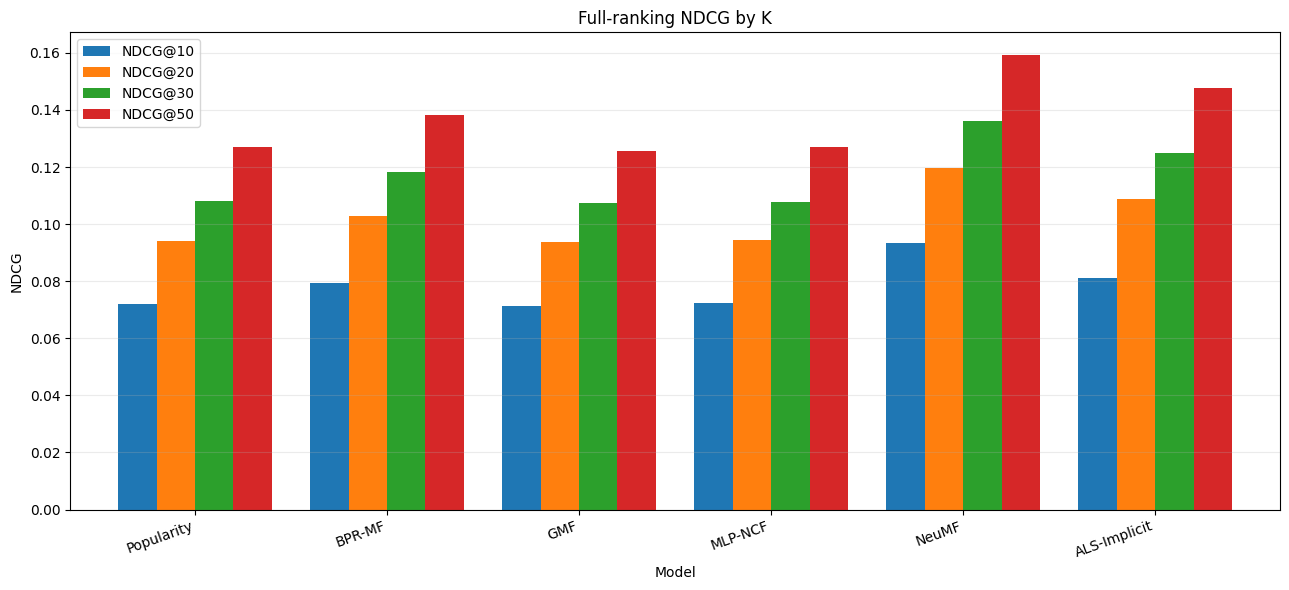

[Saved] ..\data\artifacts\cf\20261107_154606\results\ndcg_comparison.png


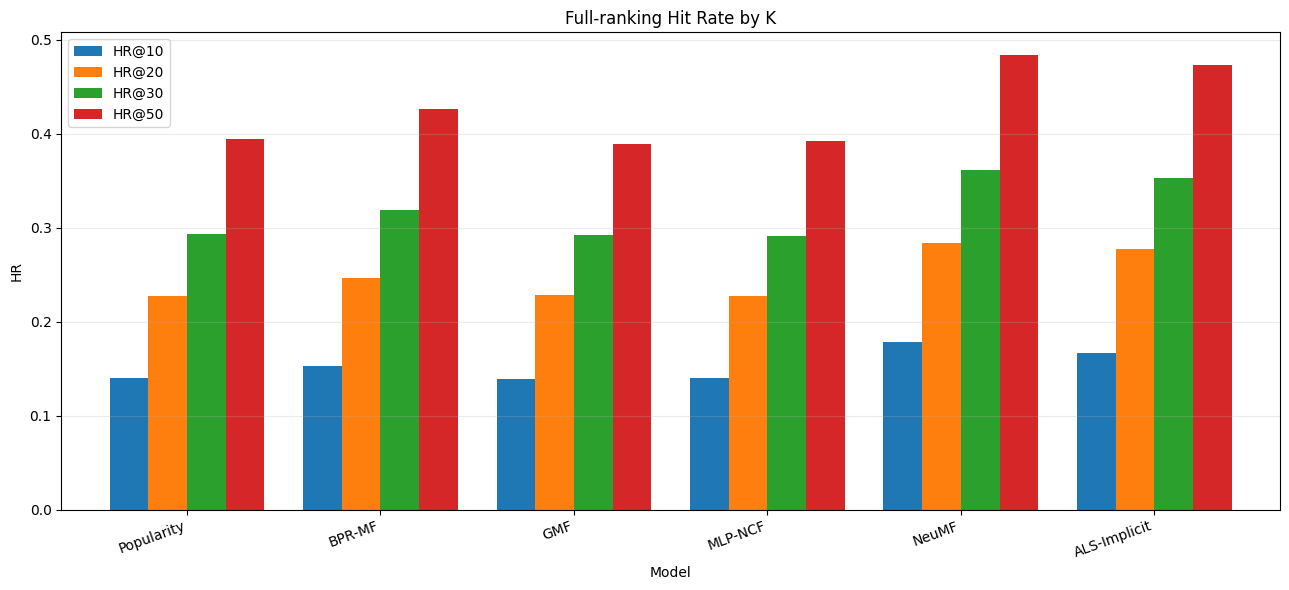

[Saved] ..\data\artifacts\cf\20261107_154606\results\hr_comparison.png


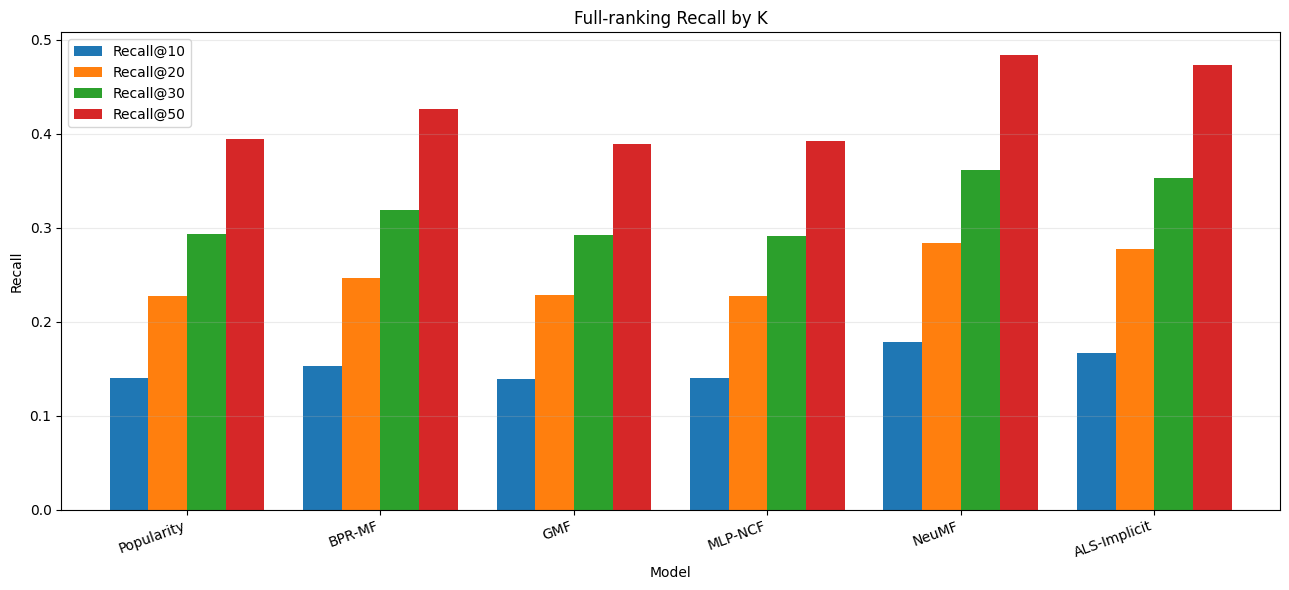

[Saved] ..\data\artifacts\cf\20261107_154606\results\recall_comparison.png


In [20]:
def plot_topk_comparison(results_df, metric_prefix, ks, title, output_path):
    columns = [f"{metric_prefix}@{k}" for k in ks]
    columns = [column for column in columns if column in results_df.columns]

    if not columns:
        print(f"No columns available for {metric_prefix}.")
        return

    ax = results_df[columns].plot(
        kind="bar",
        figsize=(13, 6),
        width=0.8,
    )
    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric_prefix)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"[Saved] {output_path}")


plot_topk_comparison(
    df_results,
    metric_prefix="NDCG",
    ks=Config.TOP_K_LIST,
    title="Full-ranking NDCG by K",
    output_path=Config.RESULT_DIR / "ndcg_comparison.png",
)

plot_topk_comparison(
    df_results,
    metric_prefix="HR",
    ks=Config.TOP_K_LIST,
    title="Full-ranking Hit Rate by K",
    output_path=Config.RESULT_DIR / "hr_comparison.png",
)

plot_topk_comparison(
    df_results,
    metric_prefix="Recall",
    ks=Config.TOP_K_LIST,
    title="Full-ranking Recall by K",
    output_path=Config.RESULT_DIR / "recall_comparison.png",
)

## Tinh chỉnh Negative Sampling

### Sampling ratio

$$
\rho=\frac{|D^-_s|}{|D^+|}
$$

Các cấu hình được so sánh: $ \rho\in\{1,4,8,16,32\} $.

Mỗi cấu hình sử dụng cùng train/validation split, cùng full-ranking validation candidates và cùng selection metric.

In [21]:
def tune_bpr_negative_ratio(
    negative_ratios=(1, 4, 8, 16, 32),
    dim=Config.EMBEDDING_DIM,
    epochs=Config.EPOCHS,
):
    rows = []

    for ratio in negative_ratios:
        set_all_seeds(Config.RANDOM_STATE)
        model = BPR_MF(num_users, num_items, dim=dim)

        checkpoint = (
            Config.CHECKPOINT_DIR / f"bpr_neg{ratio}_selection.pt"
        )
        log_path = Config.LOG_DIR / f"bpr_neg{ratio}_validation_log.csv"

        model, best_epoch, history = train_bpr(
            model=model,
            train_frame=train_df,
            num_items=num_items,
            candidate_items=train_candidate_items,
            val_frame=val_df,
            val_history=train_df,
            val_candidate_items=train_candidate_items,
            epochs=epochs,
            num_negatives=ratio,
            checkpoint_path=checkpoint,
            log_path=log_path,
            seed=Config.RANDOM_STATE,
        )

        val_metrics = evaluate_full_ranking(
            model,
            val_df,
            train_df,
            train_candidate_items,
            ks=Config.VALIDATION_K_LIST,
            verbose=False,
        )

        rows.append({
            "num_negatives": ratio,
            "best_epoch": best_epoch,
            "val_ndcg@10": val_metrics["NDCG@10"],
            "val_ndcg@20": val_metrics["NDCG@20"],
            "val_hr@10": val_metrics["HR@10"],
            "val_hr@20": val_metrics["HR@20"],
        })

    result = pd.DataFrame(rows).sort_values(
        "val_ndcg@10", ascending=False
    )
    result.to_csv(
        Config.RESULT_DIR / "bpr_negative_sampling_experiment.csv",
        index=False,
    )
    return result


RUN_NEGATIVE_SAMPLING_EXPERIMENT = False

if RUN_NEGATIVE_SAMPLING_EXPERIMENT:
    df_negative_experiment = tune_bpr_negative_ratio()
    display(df_negative_experiment)

## Lưu kết quả và cấu hình

Các artifacts của lần chạy:

- Interaction mappings.
- Train, validation và test splits.
- Model checkpoints.
- Training logs theo epoch.
- ALS validation log.
- Full-ranking Top-K metrics.
- Biểu đồ so sánh.
- Cấu hình và metadata của lần chạy.

In [22]:
run_metadata = {
    "run_id": Config.RUN_ID,
    "task": "implicit_interaction_topk_recommendation",
    "interaction_definition": "observed user-item record = positive interaction",
    "rating_used": False,
    "split": Config.TRAIN_SPLIT_NAME,
    "negative_sampler": Config.NEGATIVE_SAMPLER,
    "num_negatives_per_positive": Config.NUM_NEGATIVES,
    "validation_protocol": "full_candidate_ranking",
    "test_protocol": "full_candidate_ranking",
    "top_k": Config.TOP_K_LIST,
    "primary_metric": f"NDCG@{Config.PRIMARY_K}",
    "num_users": num_users,
    "num_items": num_items,
    "train_interactions": len(train_df),
    "validation_interactions": len(val_df),
    "test_interactions": len(test_df),
    "train_candidate_items": len(train_candidate_items),
    "test_candidate_items": len(test_candidate_items),
    "device": str(Config.DEVICE),
    "best_epochs": {
        "BPR-MF": bpr_best_epoch,
        "GMF": gmf_best_epoch,
        "MLP-NCF": mlp_best_epoch,
        "NeuMF": neumf_best_epoch,
    },
    "als_best_iterations": als_best_iterations,
}

metadata_path = Config.RUN_DIR / "run_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(run_metadata, f, ensure_ascii=False, indent=2)

print(json.dumps(run_metadata, ensure_ascii=False, indent=2))
print(f"[Saved] {metadata_path}")

{
  "run_id": "20261107_154606",
  "task": "implicit_interaction_topk_recommendation",
  "interaction_definition": "observed user-item record = positive interaction",
  "rating_used": false,
  "split": "per_user_leave_two_out",
  "negative_sampler": "uniform",
  "num_negatives_per_positive": 4,
  "validation_protocol": "full_candidate_ranking",
  "test_protocol": "full_candidate_ranking",
  "top_k": [
    10,
    20,
    30,
    50
  ],
  "primary_metric": "NDCG@10",
  "num_users": 13140,
  "num_items": 2557,
  "train_interactions": 671078,
  "validation_interactions": 13140,
  "test_interactions": 13140,
  "train_candidate_items": 2537,
  "test_candidate_items": 2545,
  "device": "cpu",
  "best_epochs": {
    "BPR-MF": 15,
    "GMF": 2,
    "MLP-NCF": 2,
    "NeuMF": 15
  },
  "als_best_iterations": 20
}
[Saved] ..\data\artifacts\cf\20261107_154606\run_metadata.json
